# Human players: sequence labels for central and peripheral players

`intermediate_strategy_characterisation.ipynb` (section 5) labels fixed-cut intermediate players by how their onset centrality changes over a session (one switch, long runs, drifter, hoverer, mixer, short runs, unclear). This notebook asks **how central and peripheral players look under the same labels**. Do they wait in one place, or do some of them also switch, drift or move in runs?

**Plan**
1. Measures and labels for every player, with a check of what a one-position player is labelled.
2. Central and peripheral players among the simulated kinds (scatter).
3. Every player's onset centrality trial by trial, grouped by label (raster).
4. Example players from each label in each group (social).

**Choices**
- Trials, the boundary (0.484, fitted on social) and the fixed-cut groups are built as in `intermediate_strategy_characterisation`, with the spawn trial dropped. `strategy_characterisation.ipynb` keeps the spawn trial (boundary 0.485), so its group counts can differ slightly.
- The labels, rules, thresholds and anchors are exactly those of `intermediate_strategy_characterisation` section 5c. Nothing is refitted for central or peripheral players.
- Two rules were tightened for this notebook, and the changes apply to both notebooks (section 1). The hoverer's middle range is narrower, and drifters need a robust change over the session. No intermediate player's priority label changed.
- Central and peripheral players with no label are called **one position**, not unclear (section 1a shows why).
- Sessions are kept apart, as in both earlier notebooks. Examples (section 4) are for social only, the main focus.

Everything that computes a number comes from `analysis/human_characterisation.py` (trials, boundary, groups, side positions) and `analysis/mixed_labels.py` (measures, anchors, labels, simulated kinds).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

import analysis.human_characterisation as hc
import analysis.mixed_labels as ml

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

LABELS = hc.SESSION_LABELS
GROUPS = ['central', 'peripheral']
STRAT_ORDER = ['central', 'intermediate', 'peripheral']
KIND_COLOURS = dict(zip(ml.SEQUENCE_KINDS, ['#55A868', '#8172B3', '#B9A0D6', '#4C72B0', '#937860', '#C44E52']))
GROUP_MARKERS = {'central': '^', 'peripheral': 's'}


def fixed_labels(frac_peripheral):
    """ Return fixed-cut labels, with 'intermediate' for players between the cuts. Takes the fractions of peripheral
        trials. """

    return hc.fixed_cut_labels(frac_peripheral).replace({'mixed': 'intermediate'})

## Load data

One row per trial per player at slice onset. The spawn trial (the first trial of each social and second-solo session) is dropped, as players start it at the arena centre. Trials are labelled peripheral below the boundary fitted on social trials. Players are central if at most 20% of their trials are peripheral, peripheral if at least 80% are, and intermediate otherwise (as in `intermediate_strategy_characterisation`).

In [2]:
# get the onset table, and drop the spawn trial (first trial of each social and second-solo session)
onset = hc.load_tables()['onset']
onset = onset[~(onset['session_type'].isin(['social', 'solo2']) & (onset['trial_pos'] == 0))]

# flag peripheral trials with the social boundary, and label players with the fixed cut
onset, split = hc.fit_trial_split(onset)
players = hc.player_table(onset)
players['fixed'] = fixed_labels(players['frac_peripheral'])
print(f"boundary {split['boundary']:.3f}, fitted on {LABELS[split['reference']]} trials")
players.groupby(['session_type', 'fixed']).size().unstack()[STRAT_ORDER].loc[list(hc.SESSION_TYPES)]

human_onset_tables: loaded from cache


boundary 0.484, fitted on social trials


fixed,central,intermediate,peripheral
session_type,,,
solo1,100,67,33
social,95,69,36
solo2,87,54,59


## 1. Measures and labels

**Motivation.** The fixed cut puts players in a group from how often they wait at the wall. It says nothing about order. A central player could wait in one place all session, or drift, or switch once while staying mostly central. The section 5c labels describe order, so running them on every player shows whether central and peripheral players have the same patterns as intermediate players.

**Method**
1. Compute the sequence measures for every player with at least 20 trials.
2. Set the anchors from central players, as in `intermediate_strategy_characterisation` 5c.
3. Give every player one label, the first rule they fit, and record every rule they pass.

**Measures** (full definitions in `intermediate_strategy_characterisation` section 5). All use onset centrality in play order.
- **Trend strength** (`trend_r2`) is the share of variation a straight line over the session explains (0 = no steady rise or fall, 1 = every trial on the line).
- **Robust change** (`drift_change`) is how far the usual position moves from the first trial to the last, from the Theil-Sen line (the median of the slopes between every pair of trials). Negative = toward the wall. Brief trips barely move it, so trips bunched early or late tilt the straight line but not this.
- **Leftover spread** (`resid_sd`) is the SD of trials around that line. Small = a narrow band.
- **Runs** (`runs_r1`) is the correlation between consecutive trials' distances from the line. About 0 = no link between trials, positive = stays on one side of the line for several trials.
- **Shifts beyond noise** (`shift_share`) is the share of trial-to-trial differences bigger than the shift cut (0 to 1).
- **Two-section fit** (`two_section_r2`, 0 to 1) is the share of variation explained by two steady sections joined by a short transition. `purity_min` (0 to 1) is the share of the less pure section's trials nearer its own level.
- **Two positions** (`gap_vs_sd`) is the gap between a player's wall-side and centre-side means divided by their within-side SD. It needs at least 5 trials on each side of the boundary, so many central and peripheral players have none.

**Labels** (in priority order, from `intermediate_strategy_characterisation` 5c)
- **one switch**: two stable sections (fit passes its shuffle test, sections differ by at least the shift cut, `purity_min` ≥ 0.80, no trip to the other level longer than 5 trials, and the two sections beat a straight line).
- **long runs**: runs pass the shuffle test and runs ≥ 0.46.
- **drifter**: trend passes the shuffle test, trend strength ≥ 0.10, and robust change at least 0.135 in size.
- **hoverer**: no significant trend, leftover spread at or below the narrow cut, and mean inside the middle range.
- **mixer**: no significant trend, wider than the narrow cut, and shift share above the shift reference.
- **short runs**: runs pass the shuffle test, but no label above fits.
- **unclear**: none of the above. For central and peripheral players this is called **one position**, as a simulated player who waits in one place with no order gets it (1a).

**Choices and assumptions**
- **The anchors come from central players** (narrow cut = their 75th percentile of leftover spread, shift cut and shift reference = 95th percentiles). Central players are therefore compared with themselves. About 25% of them are wider than the narrow cut, and about 5% are above the shift reference, by construction.
- **The middle range is narrowed** (user's choice). A hoverer waits between the two groups, near the boundary. The middle range was the typical (median) peripheral to central mean (0.151 to 0.760 in social). Run on all players, that let narrow one-position central and peripheral players inside their own group's median count as hoverers. It is now from peripheral players' 95th to central players' 5th percentile mean (`ml.middle_range`). It keeps all 8 intermediate hoverers. About 5% of each group's means still fall inside it.
- **Drifters need a robust change of at least 0.135** (user's choice, about half the shift cut). Without it, 16 of 36 social peripheral players were drifters. Most waited at the alcove while trips toward the boundary, bunched early or late, tilted their line (e.g. exp 99 p1, line change +0.16 against a robust change of +0.004). Every intermediate drifter has a robust change above 0.135.
- **The labels were checked on simulated players at intermediate positions only** (0.29 and 0.69, `intermediate_strategy_characterisation` 5a). Section 1a checks one-position players at the central and peripheral positions.

**How to read the tables**
- The first gives each anchor per session type.
- The second counts players per label in each fixed-cut group. Intermediate players are included for reference, and their labels match `intermediate_strategy_characterisation` 5c (they keep unclear).
- The third counts, per group, the players passing each label's own rule, ignoring the priority order (`fits_<label>`), so a player can count under several labels.

In [3]:
# get the sequence measures and the two-section fit for every player with at least 20 trials
seq = (ml.sequence_table(onset).merge(players[list(hc.KEYS) + ['fixed']], on=list(hc.KEYS))
       .merge(ml.two_section_table(onset).drop(columns=['section_a_end', 'section_b_start', 'level_a', 'level_b']),
              on=list(hc.KEYS), how='left'))
print('players with sequence measures:', seq.groupby('session_type').size().reindex(hc.SESSION_TYPES).to_dict())

# add each player's robust change over the session (Theil-Sen)
seq = seq.merge(ml.robust_trend_table(onset), on=list(hc.KEYS), how='left')

# add the gap-to-spread ratio (needs at least 5 trials on each side of the boundary)
sides = hc.side_positions(onset, split['boundary']).assign(gap_vs_sd=lambda d: d['gap'] / d['sd_within'])
seq = seq.merge(sides[list(hc.KEYS) + ['gap_vs_sd']], on=list(hc.KEYS), how='left')

# find the shift cut from central players' within-centre changes, and count each player's shifts
shift_cut = ml.shift_noise_cut(onset, players, split['boundary'])
shifts = ml.shift_table(onset, shift_cut)
seq = seq.merge(shifts[list(hc.KEYS) + ['shift_share']], on=list(hc.KEYS), how='left')
shift_ref = ml.shift_reference(shifts, players)

# set the hoverer cut and the middle range from central and peripheral players
central_sd = seq[seq['fixed'] == 'central'].groupby('session_type')['resid_sd'].quantile([0.5, 0.75]).unstack()
narrow_cut = central_sd[0.75]
middle = ml.middle_range(seq)
display(pd.DataFrame(dict(narrow_cut=narrow_cut, middle_low={st: m[0] for st, m in middle.items()},
                          middle_high={st: m[1] for st, m in middle.items()}, shift_cut=shift_cut,
                          shift_reference=shift_ref)).loc[list(hc.SESSION_TYPES)].round(3))

# label every player with the section 5c rules
labelled = ml.assign_labels(seq, narrow_cut, middle, shift_ref=shift_ref, gap_min=shift_cut, drift_min=ml.DRIFT_MIN)

# call unlabelled central and peripheral players 'one position' (section 1a)
in_group = labelled['fixed'].isin(GROUPS)
for col in ('label', 'all_labels'):
    labelled.loc[in_group, col] = labelled.loc[in_group, col].replace({'unclear': 'one position'})
SHOW_LABELS = list(ml.LABELS) + ['one position']

# count players per label in each group
display(pd.crosstab([labelled['session_type'], labelled['fixed']], labelled['label'], margins=True, margins_name='all')
        .reindex(index=list(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])) + [('all', '')],
                 columns=SHOW_LABELS + ['all'], fill_value=0))

# count the players passing each label's own rule, ignoring the order
FIT_COLUMNS = [l for l in ml.LABELS if l != 'unclear']
(labelled.groupby(['session_type', 'fixed'])[['fits_' + l.replace(' ', '_') for l in FIT_COLUMNS]].sum()
 .rename(columns=lambda c: c[5:].replace('_', ' ')).assign(players=labelled.groupby(['session_type', 'fixed']).size())
 .reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER])))

players with sequence measures: {'solo1': 194, 'social': 200, 'solo2': 200}


,narrow_cut,middle_low,middle_high,shift_cut,shift_reference
solo1,0.160,0.274,0.647,0.274,0.262
social,0.145,0.309,0.645,0.272,0.207
solo2,0.160,0.292,0.651,0.267,0.228


label                      one switch  long runs  drifter  hoverer  mixer  short runs  unclear  one position  all
session_type fixed                                                                                               
solo1        central                3          5       19        2      2          21        0            45   97
             intermediate          20          6       10        1     17           8        3             0   65
             peripheral            12          5        4        0      0           4        0             7   32
social       central                7          4        6        1      2          29        0            46   95
             intermediate          12         15       11        0     19           7        5             0   69
             peripheral             4          4        6        0      0          10        0            12   36
solo2        central                5          4        9        0      4          13        0            52   87
             intermediate          13          4       10        7     18           1        1             0   54
             peripheral             3          5        2        1      1          16        0            31   59
all                                79         52       77       12     63         109        9           193  594

one switch  long runs  drifter  hoverer  mixer  short runs  players
solo1  central                3          7       23        2      2          30       97
       intermediate          20         20       29        1     18          27       65
       peripheral            12         16        9        0      0           9       32
social central                7          8       12        1      2          35       95
       intermediate          12         23       35        0     20          39       69
       peripheral             4          7        7        0      0          18       36
solo2  central                5          6       11        0      4          15       87
       intermediate          13         12       21        8     18          21       54
       peripheral             3          8        3        1      1          21       59

### 1a. What a one-position player is labelled

**Motivation.** The section 5 simulated kinds sit at intermediate positions. A central or peripheral player who waits in one place, with no order in their trials, should get no order label. This checks which label such a player actually gets.

**Method.** Simulate 200 one-position players per group and session type. Each waits at the group's median mean centrality, with scatter equal to the group's median leftover spread, with no trend and no runs (the simulator's hoverer kind, moved to the group's position). Values are clipped to [0, 1]. Each player has the session type's median trial count. Label them with the same anchors as the real players.

**Assumption.** Real players' scatter is not normal. Peripheral players pile up at the alcove corners (`centrality` ≈ 0.085), so this is a rough check.

**How to read the table.** One row per group and session type, with the simulated position and spread. Each label column is the share of the simulated players given that label (before renaming, so unclear here is one position elsewhere).

In [4]:
# get the median trial count per session type, and each group's typical position and spread
lengths = players.groupby('session_type')['n_trials'].median().astype(int)
group_pos = labelled.groupby(['session_type', 'fixed'])[['mean_centrality', 'resid_sd']].median()


def simulate_one_position():
    """ Return labels for simulated one-position players at each group's typical position and spread, per session
        type. Takes no arguments. """

    parts = []
    for st in hc.SESSION_TYPES:
        for g in GROUPS:
            pos, sd = group_pos.loc[(st, g)]
            params = dict(low=pos, high=pos, spread=sd, hover_mean=pos, hover_sd=sd, run_length=10)
            sim_onset, _ = ml.simulate_sequences(lengths[st], 200, params, np.random.default_rng(lengths[st]), kinds=('hoverer',))
            sim_onset = sim_onset.assign(session_type=st)
            # measure the simulated players as the real ones
            sim = (ml.sequence_table(sim_onset)
                   .merge(ml.two_section_table(sim_onset).drop(columns=['section_a_end', 'section_b_start', 'level_a', 'level_b']),
                          on=list(hc.KEYS))
                   .merge(ml.shift_table(sim_onset, shift_cut)[list(hc.KEYS) + ['shift_share']], on=list(hc.KEYS))
                   .merge(ml.robust_trend_table(sim_onset), on=list(hc.KEYS)))
            parts.append(ml.assign_labels(sim, narrow_cut, middle, shift_ref=shift_ref, gap_min=shift_cut, drift_min=ml.DRIFT_MIN)
                         .assign(group=g, position=round(pos, 3), spread=round(sd, 3)))
    return pd.concat(parts, ignore_index=True)


sim_one = simulate_one_position()
(pd.crosstab([sim_one['session_type'], sim_one['group'], sim_one['position'], sim_one['spread']], sim_one['label'], normalize='index')
 .reindex(columns=list(ml.LABELS), fill_value=0).reindex(list(hc.SESSION_TYPES), level=0).round(2))

label                                    one switch  long runs  drifter  hoverer  mixer  short runs  unclear
session_type group      position spread                                                                     
solo1        central    0.723    0.134            0          0     0.01        0    0.0        0.04     0.96
             peripheral 0.168    0.153            0          0     0.02        0    0.0        0.05     0.93
social       central    0.760    0.124            0          0     0.00        0    0.0        0.07     0.93
             peripheral 0.151    0.119            0          0     0.00        0    0.0        0.08     0.92
solo2        central    0.762    0.118            0          0     0.01        0    0.0        0.06     0.92
             peripheral 0.145    0.069            0          0     0.00        0    0.0        0.06     0.94

**Interpretation**

All values are from the tables above (social unless stated).

- **For central and peripheral players, no label means one position.** Simulated one-position players at the typical group positions get no label (unclear) in 0.92 to 0.96 of cases, short runs in 0.04 to 0.08 and drifter in 0.00 to 0.02 (1a table). So these players are called one position here. For intermediate players, unclear still means weak or mixed signals.
- **About half of social central players wait in one position.** Of 95, 46 are one position and 29 short runs, against 7 one switch, 6 drifter, 4 long runs, 2 mixer and 1 hoverer.
- **Short runs is far more common than one position predicts.** 35 of 95 social central and 18 of 36 peripheral players pass the short runs rule (third table), against 0.07 to 0.08 of simulated one-position players. Their consecutive trials sit closer together than random order gives. Each player chooses where to start each trial, so this describes their choices.
- **The robust change removes most peripheral drifters.** Before it, 16 of 36 social peripheral players and 13 of 59 second-solo peripheral players were drifters. Now 6 and 2 are. Social peripheral short runs rose from 3 to 10 and one position from 9 to 12. No intermediate player's priority label changed.
- **The hoverer band lets a few group players through, as expected.** 1 social central, 2 first-solo central and 1 second-solo peripheral player are hoverers. The band is set so that about 5% of each group's means fall inside it.
- **Mixers are rare in the groups.** There are 2 social central and 0 peripheral mixers. The shift reference is set from central players' own sessions, so about 5% of them sit above it by construction.
- **Limits.** The anchors come from central players. The 1a check draws normal scatter, not the alcove-corner pile-up of real peripheral players.

## 2. Central and peripheral players among the simulated kinds

**Motivation.** The labels were built on simulated intermediate kinds. This shows where central and peripheral players sit on the measures that tell those kinds apart, and so how close any of them come to a kind.

**Method.** The six simulated kinds are regenerated exactly as in `intermediate_strategy_characterisation` 5a (same settings and seeds, 200 players per kind at each session type's median trial count). Real players are plotted over them.

**How to read the figure**
- One row per session type, two panels per row.
- Small faded points are simulated players, coloured by kind. Grey dots are real intermediate players, for reference. Triangles are real central players, squares real peripheral players, each in their group colour with a black edge.
- Left panel. x is trend strength (`trend_r2`) and y is runs (`runs_r1`). A drifter sits at high trend and no runs, a one-switch player at high trend and high runs, and a long-runs player at low trend and high runs. Mixers and hoverers sit near the origin.
- Right panel. x is leftover spread (`resid_sd`) and y is the two-position ratio (`gap_vs_sd`). The dotted line is 3.46, what one even spread gives when cut in two. The dashed line is central players' median leftover spread. Players with fewer than 5 trials on one side of the boundary have no ratio and are missing. The count shown in the panel is the number of central and peripheral players plotted out of all of them.

**Why it is plotted.** If central and peripheral players wait in one place, they should sit at low trend, low runs and narrow spread, near the simulated hoverers. Points among the one-switch, drifter or long-runs clouds would mean that some group players change in the same way as intermediate players, only within their own range.

simulation settings: {'low': np.float64(0.29), 'high': np.float64(0.69), 'spread': np.float64(0.11), 'hover_mean': np.float64(0.46), 'hover_sd': np.float64(0.124), 'run_length': 10}


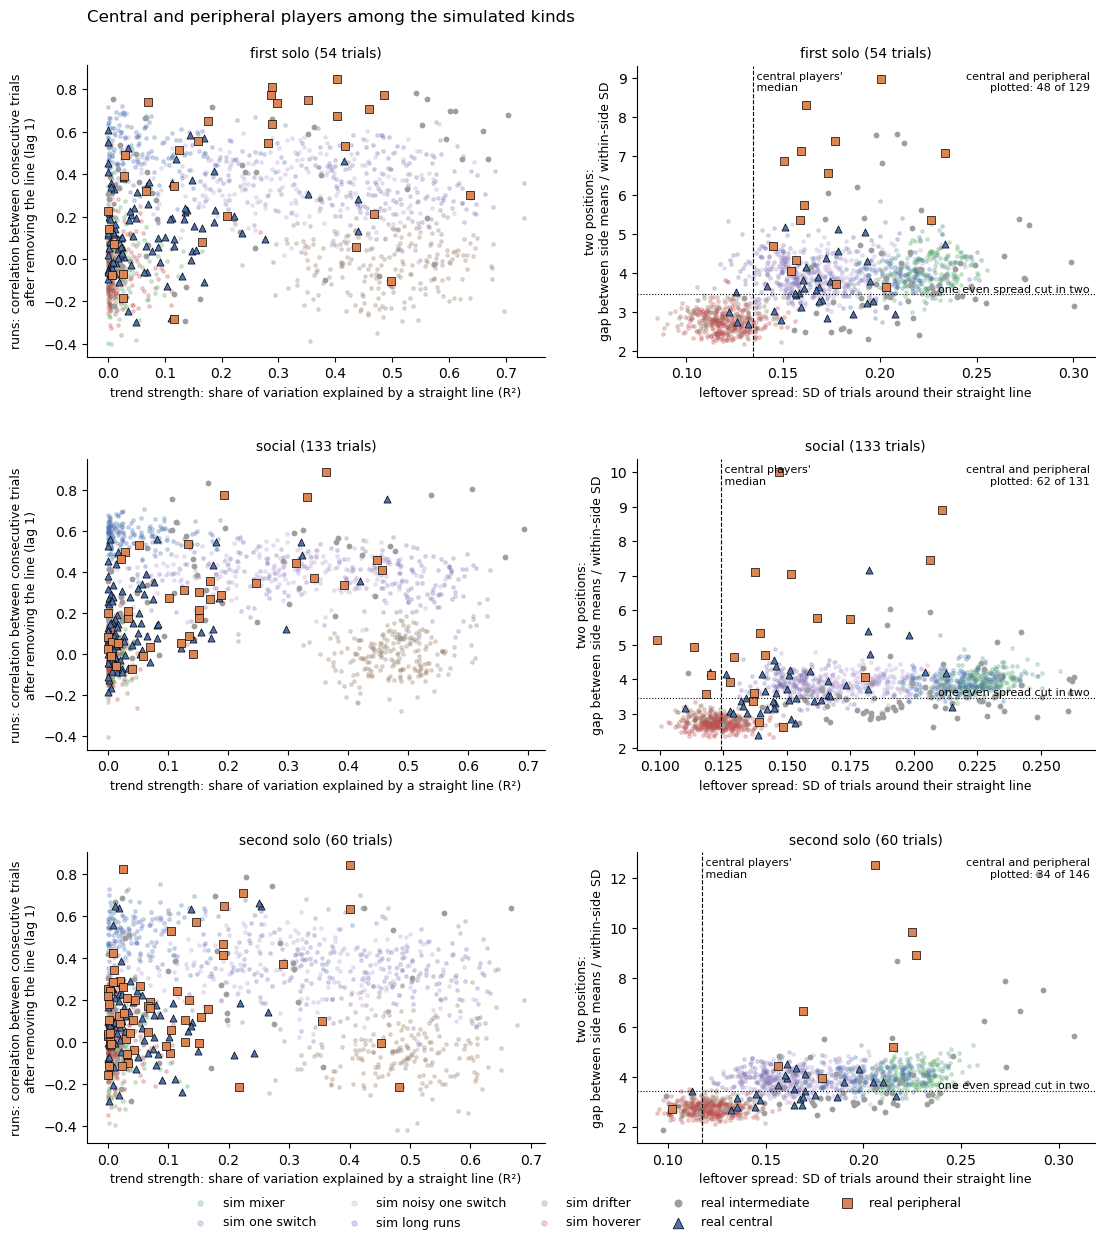

trend_r2  runs_r1  resid_sd  gap_vs_sd
solo1  central                0.04     0.12      0.13       3.52
       intermediate           0.08     0.31      0.21       3.67
       peripheral             0.19     0.44      0.15       5.76
       simulated hoverer      0.01    -0.04      0.12       2.72
social central                0.01     0.11      0.12       3.53
       intermediate           0.11     0.30      0.19       3.35
       peripheral             0.13     0.27      0.12       4.82
       simulated hoverer      0.00    -0.00      0.12       2.67
solo2  central                0.02     0.08      0.12       3.39
       intermediate           0.05     0.25      0.20       3.36
       peripheral             0.04     0.14      0.07       5.94
       simulated hoverer      0.01    -0.02      0.12       2.69

In [5]:
# rebuild the section 5a settings from intermediate players' own positions and the typical group means
own = (sides.merge(players[list(hc.KEYS) + ['fixed']], on=list(hc.KEYS)).query("fixed == 'intermediate'")
       .groupby('session_type')[['wall_mean', 'centre_mean', 'wall_sd', 'centre_sd']].median())
typical = seq.groupby(['session_type', 'fixed'])['mean_centrality'].median().unstack()[['peripheral', 'central']]
SIM_PARAMS = dict(low=round(own.loc['social', 'wall_mean'], 2), high=round(own.loc['social', 'centre_mean'], 2),
                  spread=round(own.loc['social', ['wall_sd', 'centre_sd']].mean(), 2),
                  hover_mean=round(typical.loc['social'].mean(), 2), hover_sd=round(central_sd.loc['social', 0.5], 3),
                  run_length=10)
print('simulation settings:', SIM_PARAMS)


def simulate_kinds():
    """ Return the sequence measures and gap-to-spread ratio for every simulated kind at each session type's median
        trial count. Takes no arguments. """

    parts = []
    for st in hc.SESSION_TYPES:
        sim_onset, sim_kinds = ml.simulate_sequences(lengths[st], 200, SIM_PARAMS, np.random.default_rng(lengths[st]))
        sim_sides = hc.side_positions(sim_onset, split['boundary']).assign(gap_vs_sd=lambda d: d['gap'] / d['sd_within'])
        parts.append(ml.sequence_table(sim_onset).merge(sim_kinds, on=list(hc.KEYS))
                     .merge(sim_sides[list(hc.KEYS) + ['gap_vs_sd']], on=list(hc.KEYS), how='left').assign(length_of=st))
    return pd.concat(parts, ignore_index=True)


sim_seq = simulate_kinds()
AXIS_LABELS = {'trend_r2': 'trend strength: share of variation explained by a straight line (R²)',
               'runs_r1': 'runs: correlation between consecutive trials\nafter removing the line (lag 1)',
               'resid_sd': 'leftover spread: SD of trials around their straight line',
               'gap_vs_sd': 'two positions:\ngap between side means / within-side SD'}


def plot_groups_vs_sim():
    """ Plot real central and peripheral players over the simulated kinds, as trend against runs and as leftover
        spread against the two-position ratio, one row per session type. Takes no arguments. """

    fig, axes = plt.subplots(3, 2, figsize=(13, 14), gridspec_kw=dict(hspace=0.35))
    for row, st in enumerate(hc.SESSION_TYPES):
        sim = sim_seq[sim_seq['length_of'] == st]
        real = labelled[labelled['session_type'] == st]
        for ax, (x, y) in zip(axes[row], (('trend_r2', 'runs_r1'), ('resid_sd', 'gap_vs_sd'))):
            # plot the simulated kinds, then intermediate players, then the two groups on top
            for kind in ml.SEQUENCE_KINDS:
                s = sim[sim['kind'] == kind]
                ax.scatter(s[x], s[y], s=6, color=KIND_COLOURS[kind], alpha=0.25, label=f'sim {kind}')
            s = real[real['fixed'] == 'intermediate']
            ax.scatter(s[x], s[y], s=10, color='#9E9E9E', label='real intermediate')
            for g in GROUPS:
                s = real[real['fixed'] == g]
                ax.scatter(s[x], s[y], s=26, marker=GROUP_MARKERS[g], color=hc.STRAT_PALETTE[g], edgecolor='k',
                           linewidth=0.5, label=f'real {g}')
            if y == 'gap_vs_sd':
                # mark one even spread cut in two, and central players' median leftover spread
                ax.axhline(hc.ONE_FLAT_SPLIT_RATIO, color='k', ls=':', lw=0.8)
                ax.text(0.99, hc.ONE_FLAT_SPLIT_RATIO, 'one even spread cut in two', transform=ax.get_yaxis_transform(),
                        ha='right', va='bottom', fontsize=8)
                ax.axvline(central_sd.loc[st, 0.5], color='k', ls='--', lw=0.8)
                ax.text(central_sd.loc[st, 0.5], 0.98, " central players'\n median", transform=ax.get_xaxis_transform(),
                        ha='left', va='top', fontsize=8)
                # say how many group players have a ratio
                grp = real[real['fixed'].isin(GROUPS)]
                ax.text(0.99, 0.98, f"central and peripheral\nplotted: {grp['gap_vs_sd'].notna().sum()} of {len(grp)}",
                        transform=ax.transAxes, ha='right', va='top', fontsize=8)
            ax.set_xlabel(AXIS_LABELS[x], fontsize=9)
            ax.set_ylabel(AXIS_LABELS[y], fontsize=9)
            ax.set_title(f"{LABELS[st]} ({lengths[st]} trials)", fontsize=10)
            ax.spines[['top', 'right']].set_visible(False)
    handles, names = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, names, frameon=False, fontsize=9, markerscale=1.5, ncol=5, loc='upper center',
               bbox_to_anchor=(0.5, 0.08))
    fig.suptitle('Central and peripheral players among the simulated kinds', x=0.125, y=0.92, ha='left')
    plt.show()


plot_groups_vs_sim()

# summarise the plotted measures per group, with the simulated hoverer for comparison
summary = labelled.groupby(['session_type', 'fixed'])[['trend_r2', 'runs_r1', 'resid_sd', 'gap_vs_sd']].median()
hover = (sim_seq[sim_seq['kind'] == 'hoverer'].groupby('length_of')[['trend_r2', 'runs_r1', 'resid_sd', 'gap_vs_sd']].median()
         .assign(fixed='simulated hoverer').rename_axis('session_type').set_index('fixed', append=True))
pd.concat([summary, hover]).reindex(pd.MultiIndex.from_product([hc.SESSION_TYPES, STRAT_ORDER + ['simulated hoverer']])).round(2)

**How to read the table.** Median of each plotted measure per group, with the simulated hoverer (one narrow position, no order) for comparison.

**Interpretation**

All values are from the figure and the table above.

- **Most central players sit with the simulated hoverers.** Social central medians are trend 0.01, runs 0.11 and spread 0.12. The simulated hoverer has 0.00, 0.00 and 0.12. Runs is the one measure that differs, which matches the short runs count in section 1.
- **Peripheral players have more trend and runs.** Their medians are trend 0.13 and runs 0.27 in social, 0.19 and 0.44 in the first solo, and 0.04 and 0.14 in the second solo. Several peripheral squares sit inside the simulated one-switch, noisy one-switch and long-runs clouds (left panels). Trend strength here is the straight line's, so it includes the tilt from trips that the robust change leaves out.
- **The two-positions panel shows a selected few.** Only 62 of 131 social group players have a ratio (48 of 129 in the first solo, 34 of 146 in the second). These are the players with at least 5 trials on their less-used side. The peripheral median ratio of 4.82 to 5.94 describes only that subset.
- **Limits.** The simulated kinds sit at 0.29 and 0.69, not at the group positions. Trend strength and runs are shares and correlations, so they compare across positions. Leftover spread does not compare as directly, as peripheral trials are bounded by the alcove back (second-solo peripheral median spread 0.07).

## 3. Labels trial by trial

**Motivation.** A label is a summary of several measures. The raster shows the trials behind it, so each label can be checked by eye in the two groups.

**How to read the figure**

**Colour shows each trial's onset centrality value, not a label.** Orange is 0 (alcove back), white 0.5 and blue 1 (arena centre), on a continuous scale (colour bar). Grey fills the end of shorter sessions.
- One column per session type, one row of panels per group (central on top, peripheral below).
- Each row in a panel is one player, and each column one trial in play order.
- Rows are grouped by label (priority order), with the label and count on the left. Within a label, rows are sorted by mean centrality.

**Why it is plotted.** A central player who waits in one place (one position) shows an even blue row, and a peripheral one an even orange row. One switch should show one colour change, long runs long blocks, a drifter a gradual fade, and a mixer a speckled row.

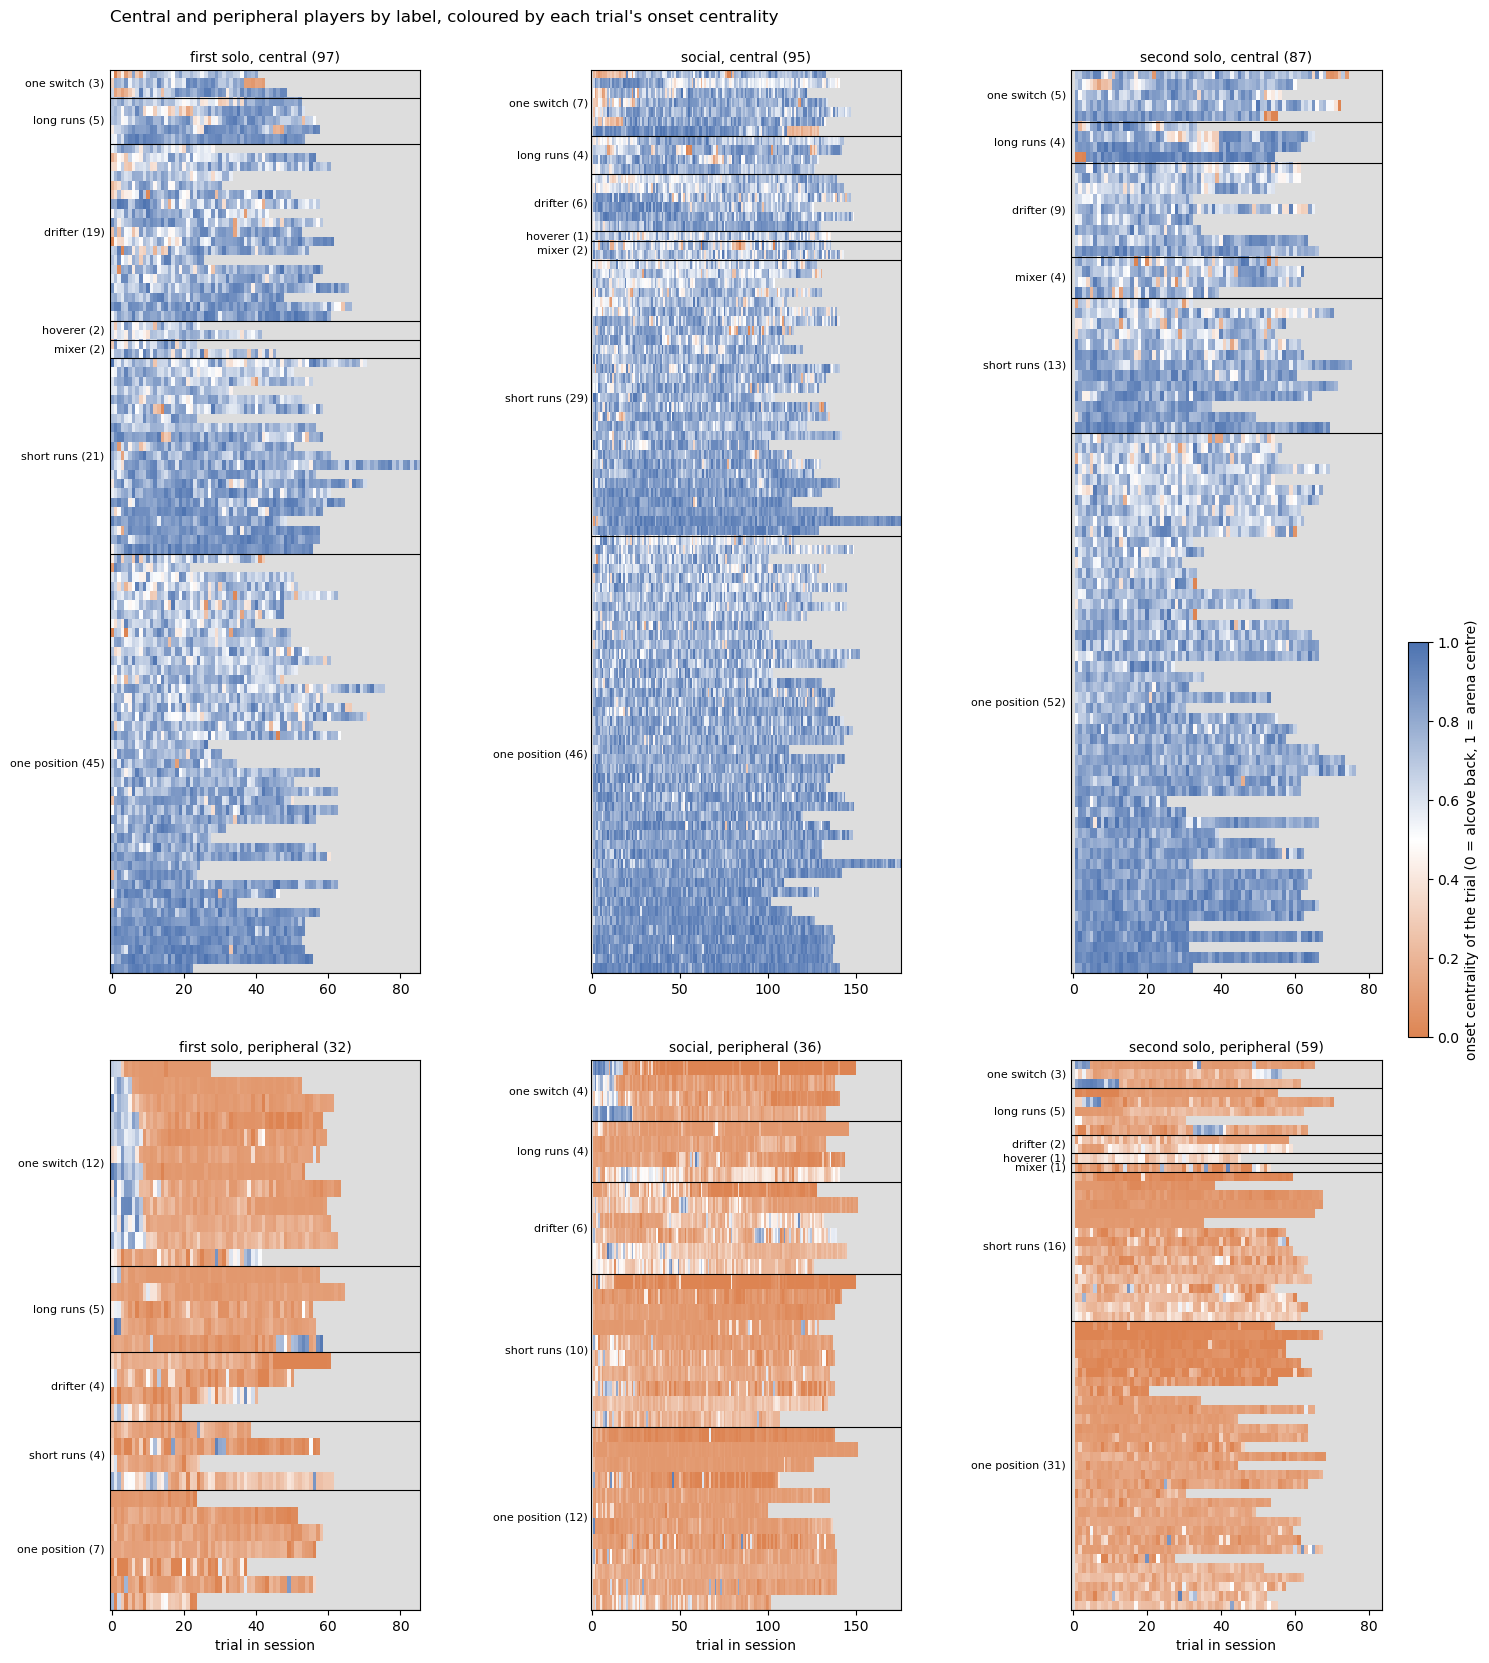

players  toward_wall  median_line_change  median_drift_change  median_section_gap  median_switch_at
session_type fixed      label                                                                                                          
solo1        central    drifter          19            6                0.17                 0.16                0.11              0.40
                        one switch        3            1                0.43                 0.30                0.40              0.23
             peripheral drifter           4            3               -0.24                -0.19               -0.18              0.56
                        one switch       12           11               -0.37                -0.05               -0.53              0.15
social       central    drifter           6            3               -0.00                -0.00                0.02              0.34
                        one switch        7            3                0.28                 0.14                0.37              0.16
             peripheral drifter           6            4               -0.25                -0.22               -0.17              0.49
                        one switch        4            4               -0.43                -0.07               -0.62              0.13
solo2        central    drifter           9            5               -0.14                -0.14               -0.10              0.56
                        one switch        5            4               -0.14                -0.08               -0.34              0.91
             peripheral drifter           2            1               -0.01                 0.01                0.03              0.36
                        one switch        3            2               -0.24                -0.01               -0.58              0.20

In [6]:
def plot_group_rasters():
    """ Plot every central and peripheral player's onset centrality trial by trial, grouped by label, one row of panels
        per group and one column per session type. Takes no arguments. """

    cmap = LinearSegmentedColormap.from_list('wall_centre', [hc.STRAT_PALETTE['peripheral'], '#FFFFFF', hc.STRAT_PALETTE['central']])
    cmap.set_bad('#DDDDDD')
    order = {lab: i for i, lab in enumerate(SHOW_LABELS)}
    n_rows = labelled.groupby(['fixed', 'session_type']).size()
    fig, axes = plt.subplots(2, 3, figsize=(17, 20), gridspec_kw=dict(height_ratios=[n_rows[g].max() for g in GROUPS],
                                                                      wspace=0.55, hspace=0.12))
    for r, g in enumerate(GROUPS):
        for ax, st in zip(axes[r], hc.SESSION_TYPES):
            sub = (labelled[(labelled['session_type'] == st) & (labelled['fixed'] == g)]
                   .assign(rank=lambda d: d['label'].map(order)).sort_values(['rank', 'mean_centrality']))
            trials = onset[onset['session_type'] == st]
            # fill one row per player with their trial centralities in play order
            mat = np.full((len(sub), int(trials['trial_pos'].max()) + 1), np.nan)
            for row, (e, p) in enumerate(zip(sub['experiment'], sub['player'])):
                t = trials[(trials['experiment'] == e) & (trials['player'] == p)]
                mat[row, t['trial_pos'].to_numpy(int)] = t['centrality'].to_numpy()
            image = ax.imshow(mat, aspect='auto', cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
            # separate and name the label groups
            edges = np.r_[0, np.cumsum(sub['label'].value_counts().reindex(SHOW_LABELS, fill_value=0).to_numpy())]
            for lab, lo, hi in zip(SHOW_LABELS, edges[:-1], edges[1:]):
                if hi > lo:
                    ax.axhline(hi - 0.5, color='k', lw=0.8)
                    ax.text(-2, (lo + hi - 1) / 2, f'{lab} ({hi - lo})', ha='right', va='center', fontsize=8)
            ax.set_yticks([])
            ax.set_title(f'{LABELS[st]}, {g} ({len(sub)})', fontsize=10)
            if r == 1:
                ax.set_xlabel('trial in session')
    # show the colour scale, which is each trial's own centrality
    bar = fig.colorbar(image, ax=axes, fraction=0.015, pad=0.02)
    bar.set_label('onset centrality of the trial (0 = alcove back, 1 = arena centre)')
    fig.suptitle("Central and peripheral players by label, coloured by each trial's onset centrality", x=0.125, y=0.91, ha='left')
    plt.show()


plot_group_rasters()

# summarise which way one-switch players and drifters move, per group
moves = labelled[labelled['fixed'].isin(GROUPS) & labelled['label'].isin(['one switch', 'drifter'])]
(moves.assign(toward_wall=moves['trend_change'] < 0)
 .groupby(['session_type', 'fixed', 'label'])
 .agg(players=('trend_change', 'size'), toward_wall=('toward_wall', 'sum'), median_line_change=('trend_change', 'median'),
      median_drift_change=('drift_change', 'median'), median_section_gap=('section_gap', 'median'),
      median_switch_at=('switch_at', 'median'))
 .reindex(list(hc.SESSION_TYPES), level=0).round(2))

**How to read the table.** One row per group and label (one switch and drifter only). `toward_wall` counts players whose straight line falls over the session. `median_line_change` is the median rise of that line from first to last trial, `median_drift_change` the median robust change, and `median_section_gap` the median of section B's mean minus section A's (negative = toward the wall in both). `median_switch_at` is the median point of the switch (0 to 1 through the session), filled for every player but meaningful for one switch only.

**Interpretation**

All values are from the figure and the table above.

- **Most group one-switch players start at the other position and switch early.** All 4 social peripheral one-switch players move toward the wall (median section gap −0.62, switch at 0.13 of the session). In the first solo it is 11 of 12 (gap −0.53, switch at 0.15). Social central one-switch players mostly move the other way (median gap +0.37, switch at 0.16, 4 of 7 toward the centre). These players settle at their group's position over roughly the first sixth of the session. Their robust change is small (median −0.07 for social peripheral), as a short first section barely moves the usual position. One switch is given before drifter, so the drift cut does not affect them.
- **The remaining peripheral drifters mostly move toward the wall.** In social 4 of 6 do (median robust change −0.22), and in the first solo 3 of 4 (−0.19). 2 are left in the second solo.
- **Central drifters differ by session.** First-solo central drifters mostly move toward the centre (13 of 19, median robust change +0.16). Social central drifters are split (3 of 6 toward the wall). Second-solo central drifters lean toward the wall (5 of 9, median −0.14).
- **Second-solo central one-switch players switch late, toward the wall.** Their median switch is at 0.91 of the session, with a gap of −0.34 (5 players).
- **One-position rows are even.** Central one-position rows are evenly blue and peripheral ones evenly orange in every session (figure).

## 4. Example players (social)

**Motivation.** The raster shows every player but is hard to read for one player. Line plots of a few typical players per label show what each label looks like within a group.

**Method**
1. Take every social central and peripheral player.
2. Scale five measures (trend strength, runs, leftover spread, shift share and two-section fit) by their SD over all social players.
3. Within each group and label, find each player's distance from the label's median on the scaled measures.
4. Plot up to 4 players nearest the median, nearest first.

**Choice.** Examples are typical players, not edge cases (user's choice). The five measures are the ones the labels are built from. Mean centrality is left out, so the examples are not chosen for position.

**How to read the figures**
- One figure per group, one row per label in that group (priority order), up to 4 players per row. The row's label and player count are on the left.
- x is the trial in the session (the spawn trial is dropped, so social starts at trial 1), and y is onset centrality (1 = arena centre, 0 = alcove back).
- Grey points joined by a thin line are each trial. The black line is the player's straight-line fit. The dashed line is the trial boundary (0.484). The shaded band is the hoverer's middle range.
- Each panel's title gives the experiment and player, their mean centrality and every label the player passes (`all_labels`, priority label first). The next lines give the trend strength, runs, robust change, leftover spread and shift share.

**Why it is plotted.** To check by eye what each label means for central and peripheral players, e.g. whether a central drifter slides toward the boundary or only moves within the centre.

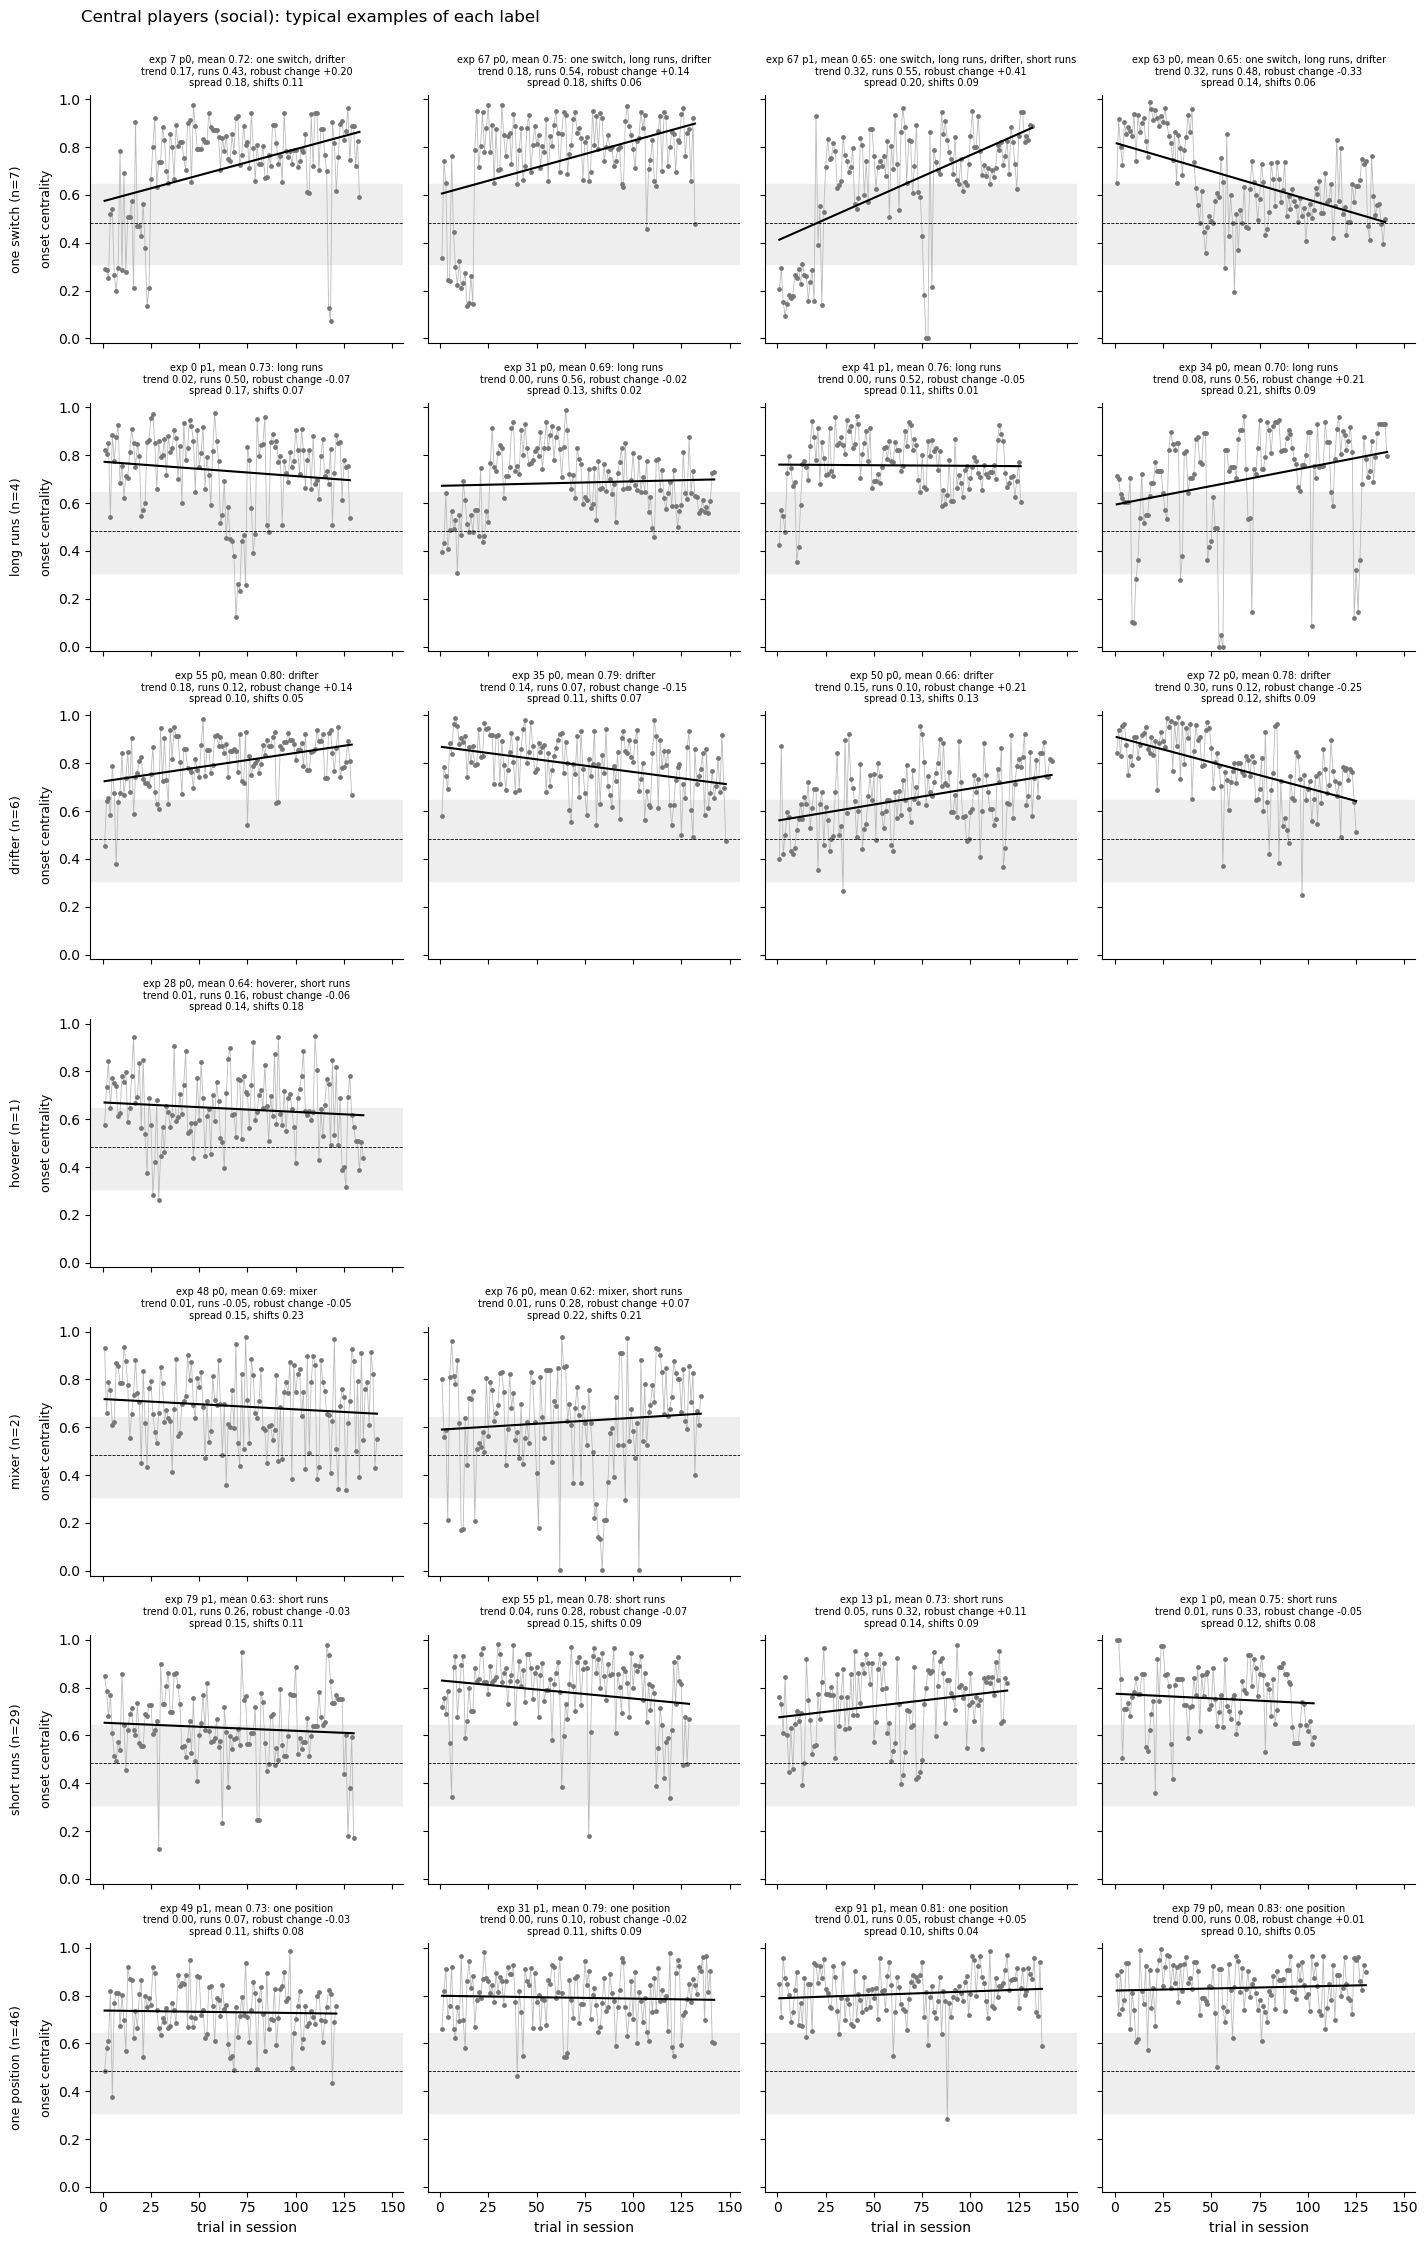

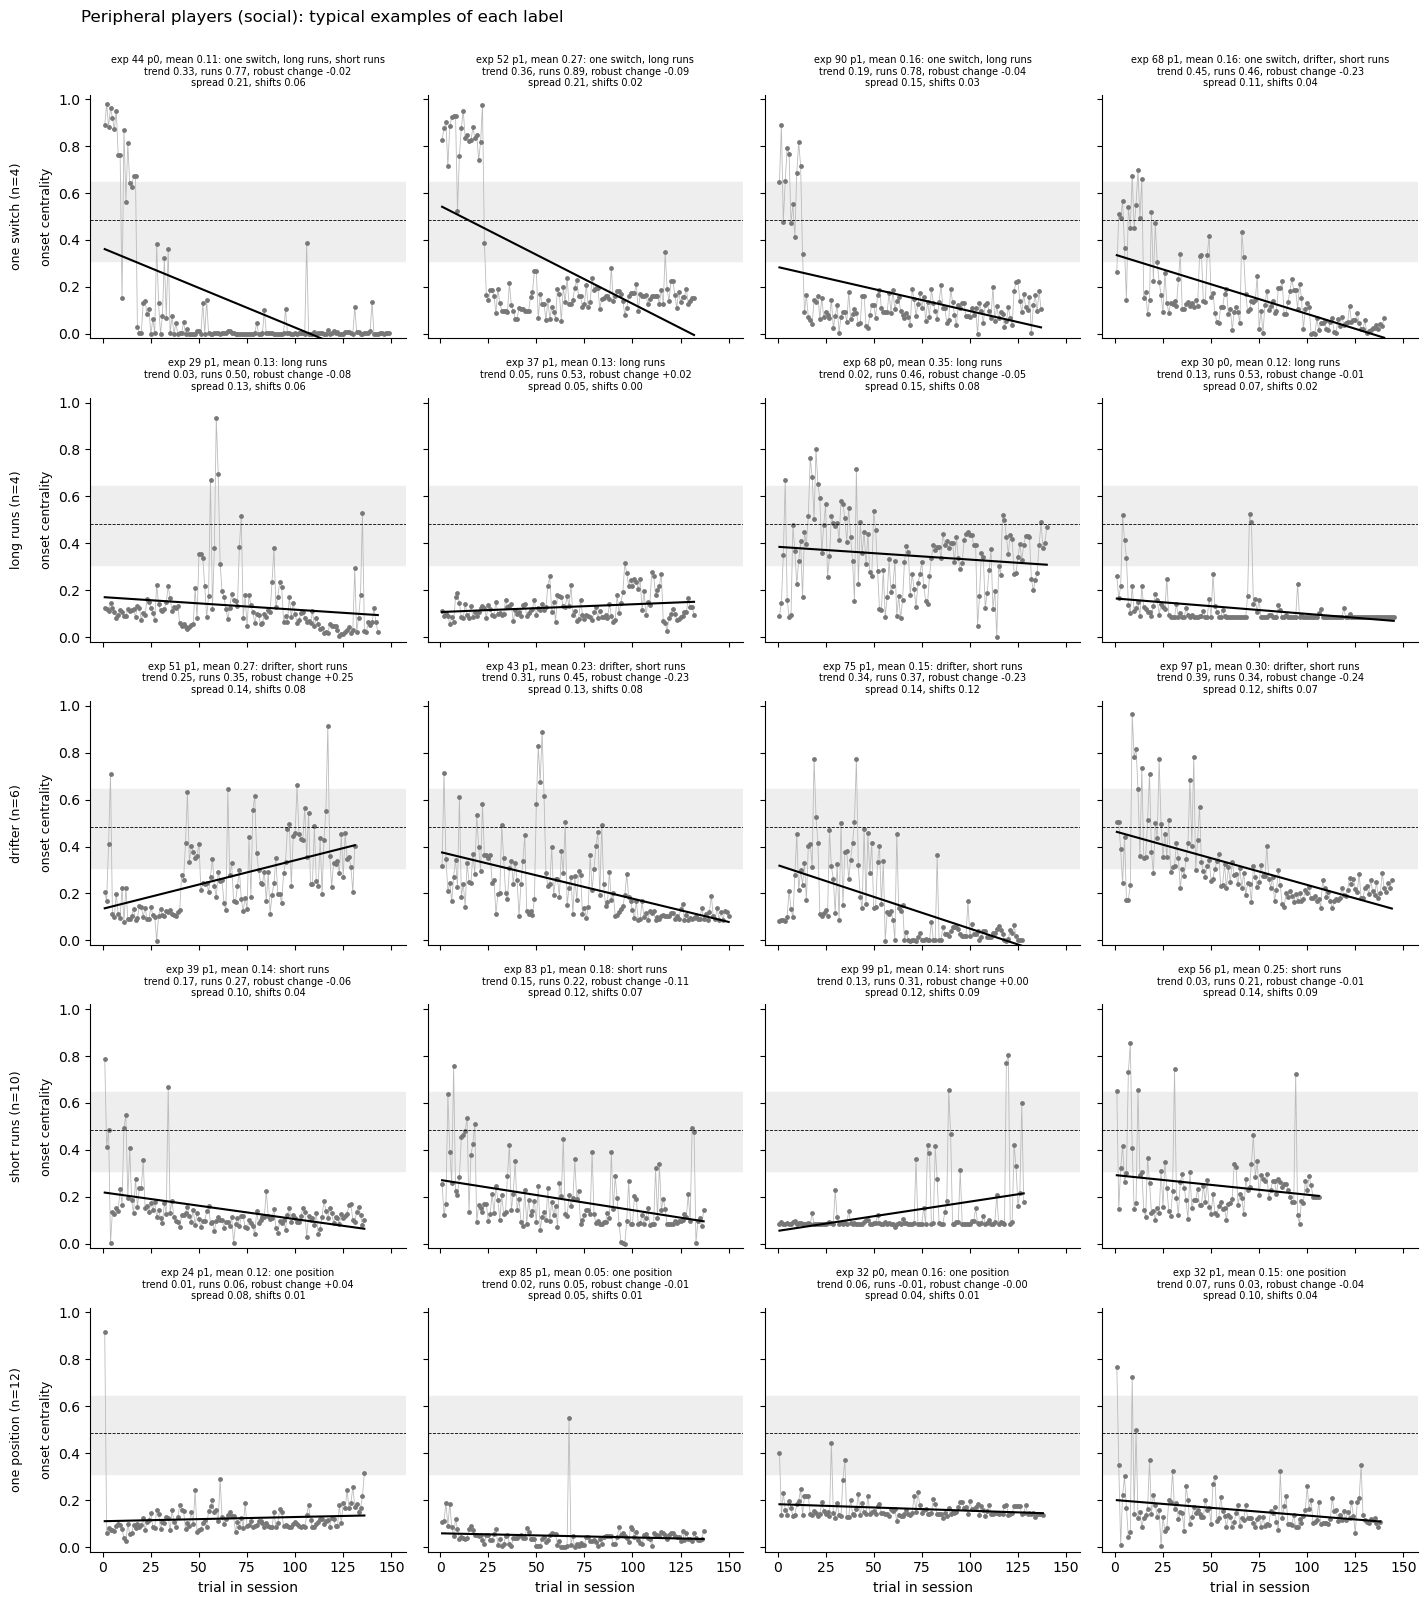

In [7]:
EX_MEASURES = ['trend_r2', 'runs_r1', 'resid_sd', 'shift_share', 'two_section_r2']
N_EXAMPLES = 4


def pick_examples(st='social', n=N_EXAMPLES):
    """ Return up to n players per group and label nearest the label's median on the scaled measures. Takes a session
        type and the number per label. """

    sub = labelled[labelled['session_type'] == st]
    # scale each measure by its SD over all players in the session
    scaled = sub[EX_MEASURES] / sub[EX_MEASURES].std()
    picks = []
    for (g, lab), grp in sub[sub['fixed'].isin(GROUPS)].groupby(['fixed', 'label']):
        # get each player's distance from the label's median within the group
        dist = np.sqrt(((scaled.loc[grp.index] - scaled.loc[grp.index].median()) ** 2).sum(axis=1))
        picks.append(grp.assign(distance=dist, n_label=len(grp)).nsmallest(n, 'distance'))
    return pd.concat(picks)


def plot_examples(examples, group, st='social'):
    """ Plot each example player's onset centrality trial by trial with their straight-line fit, one row per label.
        Takes the example players, a group and a session type. """

    ex = examples[examples['fixed'] == group]
    rows = [lab for lab in SHOW_LABELS if (ex['label'] == lab).any()]
    fig, axes = plt.subplots(len(rows), N_EXAMPLES, figsize=(3.6 * N_EXAMPLES, 3.2 * len(rows)), sharex=True, sharey=True,
                             squeeze=False)
    trials = onset[onset['session_type'] == st]
    for r, lab in enumerate(rows):
        players_here = ex[ex['label'] == lab].sort_values('distance')
        for c in range(N_EXAMPLES):
            ax = axes[r, c]
            if c >= len(players_here):
                ax.axis('off')
                continue
            row = players_here.iloc[c]
            t = trials[(trials['experiment'] == row['experiment']) & (trials['player'] == row['player'])].sort_values('trial_pos')
            x, y = t['trial_pos'].to_numpy(), t['centrality'].to_numpy()
            # shade the hoverer's middle range, then plot every trial and the straight-line fit
            ax.axhspan(*middle[st], color='#EEEEEE', zorder=0)
            ax.plot(x, y, color='#BBBBBB', lw=0.6, zorder=1)
            ax.scatter(x, y, s=6, color='#777777', zorder=2)
            ax.plot(x, np.polyval(np.polyfit(x, y, 1), x), color='k', lw=1.5, zorder=3)
            ax.axhline(split['boundary'], color='k', ls='--', lw=0.6)
            ax.set_title(f"exp {row['experiment']} p{row['player']}, mean {row['mean_centrality']:.2f}: {row['all_labels']}\n"
                         f"trend {row['trend_r2']:.2f}, runs {row['runs_r1']:.2f}, robust change {row['drift_change']:+.2f}\n"
                         f"spread {row['resid_sd']:.2f}, shifts {row['shift_share']:.2f}", fontsize=7)
            ax.set_ylim(-0.02, 1.02)
            ax.spines[['top', 'right']].set_visible(False)
        axes[r, 0].set_ylabel(f"{lab} (n={players_here['n_label'].iloc[0]})\n\nonset centrality", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel('trial in session')
    fig.suptitle(f'{group.capitalize()} players ({LABELS[st]}): typical examples of each label', x=0.06, y=1.0, ha='left')
    fig.tight_layout()
    plt.show()


examples = pick_examples()
for g in GROUPS:
    plot_examples(examples, g)

**Interpretation**

All values are from the panel titles above (social).

- **Central one-position and short-runs players wait in one place.** The one-position examples have trend 0.00 to 0.01, robust change −0.03 to +0.05 and spread 0.10 to 0.11. The short-runs examples have trend 0.01 to 0.05, spread 0.12 to 0.15 and runs 0.26 to 0.33. Their trials stay in one band, and neighbouring trials sit close together.
- **Central one switch is mostly an early start at the wall.** Three of the four examples (exp 7 p0, 67 p0 and 67 p1) wait below the boundary for about the first 10 to 25 trials, then wait centrally. Exp 63 p0 instead moves from about 0.85 to about 0.5 (robust change −0.33), and also passes the drifter rule.
- **Central long runs are runs of trips toward the wall.** E.g. exp 0 p1 waits near the wall for a block of about 10 trials mid-session.
- **Central drifters move within the centre.** The examples have robust changes of −0.25 to +0.21, and their lines stay above about 0.55.
- **The one social central hoverer is an edge case of the band.** Exp 28 p0 has mean 0.64, just under the band's 0.645 top. Most of their trials sit above the band, so they wait at the inner edge of the central group, not at the boundary.
- **Peripheral one switch is an early start at the centre.** All four examples wait centrally or near the boundary for about the first 10 to 25 trials, then at the wall.
- **Peripheral drifters now move their usual position.** Exp 51 p1 rises from about 0.1 to 0.4 (robust change +0.25). Exp 43 p1, 75 p1 and 97 p1 slide toward the wall (−0.23, −0.23 and −0.24).
- **Players whose trips tilted their line are now short runs.** Exp 99 p1 (robust change +0.00), 39 p1 (−0.06) and 83 p1 (−0.11) wait at the alcove with trips toward the boundary, bunched late (99 p1) or early (39 p1, 83 p1).
- **Peripheral one-position players wait at the alcove.** The examples have spread 0.04 to 0.10 and robust change −0.04 to +0.04.